# Ballon d'Or 2026: what the numbers say about the winner

**Question.** Harry Kane won the 2026 Ballon d'Or. Was it the best season of the ten finalists, or did the vote reward something else - volume, big games, trophies?

**Data.** Every match of the top-10 nominees in the 2025/26 evaluation window (August 2025 – July 2026, all competitions, 575 player-matches), scraped from SofaScore and Wikipedia by the ETL in [`etl/`](../etl) and loaded into a DuckDB warehouse. Every number below comes from a SQL file in [`sql/analysis/`](../sql/analysis).

**Contents**
1. Data overview and quality checks
2. Volume vs efficiency
3. Big games
4. Trophies
5. Finishing vs expected goals
6. Can a simple index predict the vote? (+ sensitivity to the weights)
7. How close was the vote?
8. The winner's season, match by match
9. Conclusions and limitations

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))     # repository root, for the analysis package

import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.stats import spearmanr

from analysis import charts, style
from analysis.warehouse import analysis_queries, connect, run

style.apply()
pd.set_option("display.precision", 2)
con = connect()

def show_sql(key):
    display(Markdown(f"```sql\n{analysis_queries()[key].read_text(encoding='utf-8').strip()}\n```"))

## 1. Data overview and quality checks

In [2]:
con.execute('''
    SELECT 'player-matches' AS item, count(*) AS n FROM FactPlayerMatch
    UNION ALL SELECT 'nominees with match data', count(DISTINCT PlayerID) FROM FactPlayerMatch
    UNION ALL SELECT 'competitions', count(DISTINCT CompetitionID) FROM FactPlayerMatch
    UNION ALL SELECT 'teams (incl. opponents)', count(*) FROM DimTeam
    UNION ALL SELECT 'players in the vote', count(*) FROM FactVoting
''').df()

,item,n
0,player-matches,575
1,nominees with match data,10
2,competitions,24
3,teams (incl. opponents),182
4,players in the vote,30


In [ ]:
# Quality checks: keys are unique, every match has a known competition and opponent,
# minutes are within a match and how much of the playing time has xG.
con.execute('''
    SELECT
        count(*) - count(DISTINCT MatchID || player)                           AS duplicate_rows,
        count(*) FILTER (WHERE competition IS NULL)                            AS unknown_competition,
        count(*) FILTER (WHERE opponent IS NULL)                               AS unknown_opponent,
        count(*) FILTER (WHERE minutes NOT BETWEEN 1 AND 130)                  AS minutes_out_of_range,
        round(100.0 * sum(minutes) FILTER (WHERE xG IS NOT NULL) / sum(minutes), 1) AS minutes_with_xg_pct
    FROM v_match
''').df()

,duplicate_rows,unknown_competition,unknown_opponent,minutes_out_of_range,minutes_with_xg_pct
0,0,0,0,0,79.4


No duplicates or broken keys. About a fifth of the minutes have no xG (most domestic cups, qualifiers and friendlies), so **every xG comparison below uses the matches with xG only**.

## 2. Volume vs efficiency

In [4]:
show_sql("01")

```sql
-- Q1. Did the winner have the best season, or just the biggest one?
-- Volume (goals, NP G+A) against efficiency (NP G+A per 90) and penalty dependence.
SELECT
    vote_rank,
    player,
    goals,
    penalty_goals,
    round(100.0 * penalty_goals / nullif(goals, 0), 1)          AS penalty_share_pct,
    np_ga,
    round(np_ga_per90, 2)                                       AS np_ga_per90,
    rank() OVER (ORDER BY goals DESC)                           AS goals_rank,
    rank() OVER (ORDER BY np_ga DESC)                           AS np_ga_rank,
    rank() OVER (ORDER BY np_ga_per90 DESC)                     AS per90_rank,
    rank() OVER (ORDER BY penalty_goals * 1.0 / nullif(goals, 0) DESC) AS penalty_share_rank
FROM v_nominee
ORDER BY vote_rank;
```

In [5]:
q1 = run(con, "01")
q1

,vote_rank,player,goals,penalty_goals,penalty_share_pct,np_ga,np_ga_per90,goals_rank,np_ga_rank,per90_rank,penalty_share_rank
0,1,Harry Kane,74,20,27.0,62,1.03,1,4,5,1
1,2,Kylian Mbappé,60,15,25.0,59,1.07,2,5,3,2
2,3,Lamine Yamal,25,6,24.0,40,0.78,7,6,8,3
3,4,Rodri,2,0,0.0,2,0.06,10,10,10,9
4,5,Lionel Messi,46,4,8.7,73,1.50,4,1,1,6
5,6,Khvicha Kvaratskhelia,23,1,4.3,32,0.82,8,8,7,7
6,7,Ousmane Dembélé,26,5,19.2,35,1.07,6,7,4,4
7,8,Erling Haaland,59,6,10.2,64,1.11,3,2,2,5
8,9,Michael Olise,29,1,3.4,63,1.03,5,3,6,8
9,10,Fabián Ruiz,3,0,0.0,9,0.31,9,9,9,9


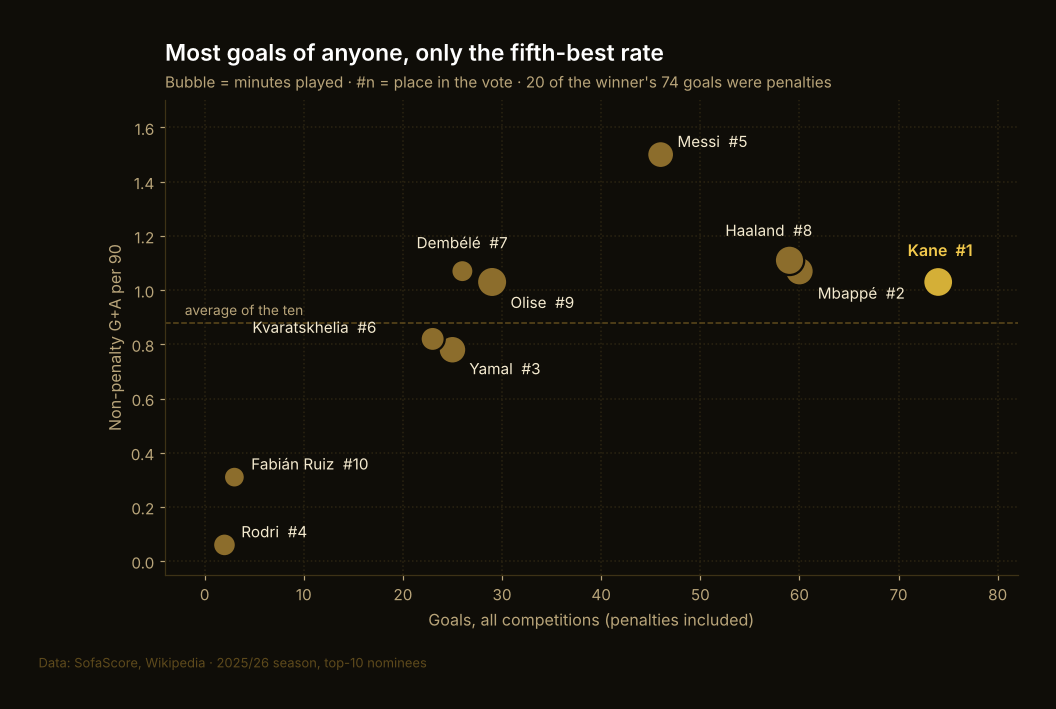

In [6]:
fig = charts.volume_vs_efficiency(q1.merge(con.execute("SELECT player, minutes FROM v_nominee").df(), on="player"))

**Takeaway.** Kane scored **74 goals**, 14 more than anyone, but **20 were penalties** (27%, the highest share of the ten). Per 90 minutes and without penalties he is **5th of 10** (1.03), behind Messi (1.50), Haaland (1.11), Mbappé and Dembélé (1.07). Voters rewarded volume.

## 3. Big games

In [7]:
show_sql("02")

```sql
-- Q2. Who delivered on the big stage?
-- G+A in Champions League and World Cup knockouts and the rating there against the season rating.
WITH ko AS (
    SELECT player,
           count(*)                         AS ko_matches,
           sum(goals + assists)             AS ko_ga,
           avg(rating)                      AS ko_rating
    FROM v_match
    WHERE is_big_stage AND is_knockout
    GROUP BY player
),
season AS (
    SELECT player, avg(rating) AS season_rating
    FROM v_match
    GROUP BY player
)
SELECT
    n.vote_rank,
    n.player,
    coalesce(ko.ko_matches, 0)::INT                     AS big_stage_ko_matches,
    coalesce(ko.ko_ga, 0)::INT                          AS big_stage_ko_ga,
    rank() OVER (ORDER BY coalesce(ko.ko_ga, 0) DESC)   AS ko_ga_rank,
    round(s.season_rating, 2)                           AS season_rating,
    round(ko.ko_rating, 2)                              AS ko_rating,
    round(ko.ko_rating - s.season_rating, 2)            AS rating_uplift
FROM v_nominee n
LEFT JOIN ko     ON ko.player = n.player
LEFT JOIN season s ON s.player = n.player
ORDER BY n.vote_rank;
```

In [8]:
q2 = run(con, "02")
q2

,vote_rank,player,big_stage_ko_matches,big_stage_ko_ga,ko_ga_rank,season_rating,ko_rating,rating_uplift
0,1,Harry Kane,9,12,1,7.75,7.66,-0.09
1,2,Kylian Mbappé,8,8,4,7.77,7.50,-0.27
2,3,Lamine Yamal,9,4,7,7.84,7.60,-0.24
3,4,Rodri,7,0,10,7.38,7.56,0.17
4,5,Lionel Messi,5,6,6,8.50,8.62,0.12
5,6,Khvicha Kvaratskhelia,9,10,2,7.36,7.96,0.59
6,7,Ousmane Dembélé,12,10,2,7.46,7.51,0.05
7,8,Erling Haaland,5,4,7,7.40,7.24,-0.16
8,9,Michael Olise,9,8,4,7.70,7.78,0.08
9,10,Fabián Ruiz,8,1,9,7.01,6.83,-0.18


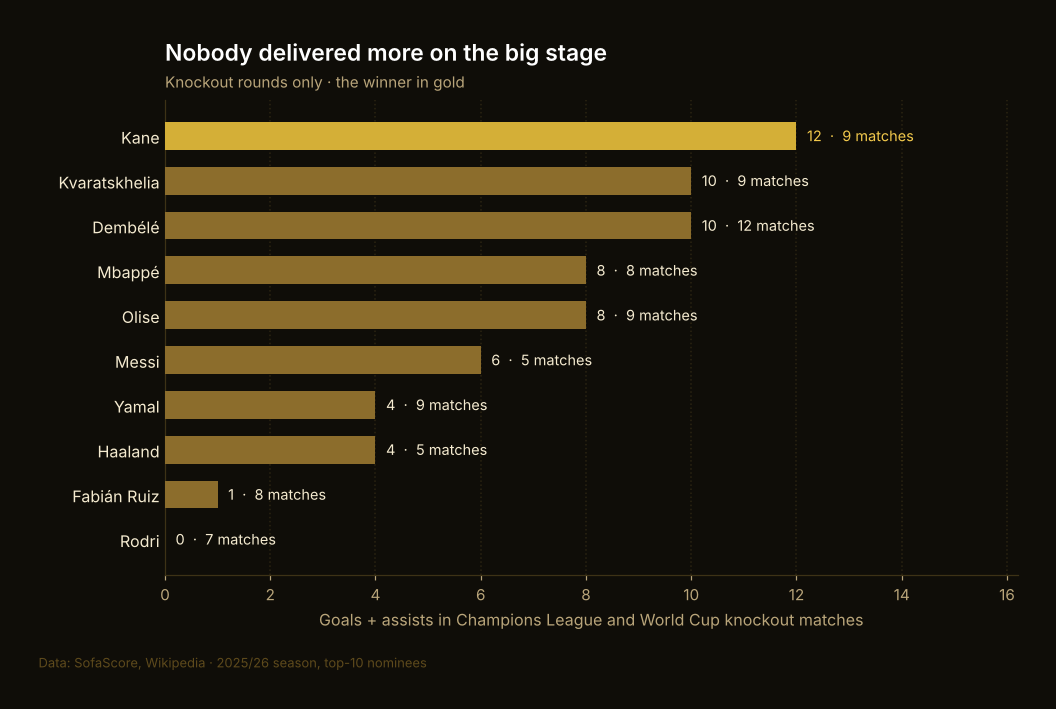

In [9]:
fig = charts.big_games(q2)

**Takeaway.** **12 goals and assists** in Champions League and World Cup knockout matches - the most of the ten (Kvaratskhelia and Dembélé: 10). His rating in those matches was slightly *below* his season average (−0.09), so it was output, not overall performance, that stood out.

## 4. Trophies

In [10]:
show_sql("03")

```sql
-- Q3. Did trophies decide the vote?
-- Trophies, weighted trophy score and how far the player got in the two big tournaments.
WITH stage AS (
    SELECT p.PlayerName AS player,
           max(CASE WHEN c.CompetitionName = 'UEFA Champions League' THEN pc.StageReached END) AS ucl_stage,
           max(CASE WHEN c.CompetitionName = 'FIFA World Cup'        THEN pc.StageReached END) AS world_cup_stage
    FROM FactPlayerCompetition pc
    JOIN DimPlayer      p ON p.PlayerID      = pc.PlayerID
    JOIN DimCompetition c ON c.CompetitionID = pc.CompetitionID
    GROUP BY p.PlayerName
)
SELECT
    n.vote_rank,
    n.player,
    n.trophies_won,
    n.major_trophies,
    n.trophy_score,
    rank() OVER (ORDER BY n.trophy_score DESC) AS trophy_rank,
    s.ucl_stage,
    s.world_cup_stage
FROM v_nominee n
LEFT JOIN stage s ON s.player = n.player
ORDER BY n.vote_rank;
```

In [11]:
q3 = run(con, "03")
rho, p = spearmanr(q3.vote_rank, q3.trophy_rank)
display(q3)
print(f"Spearman correlation, trophy rank vs vote rank: rho = {rho:+.2f} (p = {p:.2f}, n = 10)")

,vote_rank,player,trophies_won,major_trophies,trophy_score,trophy_rank,ucl_stage,world_cup_stage
0,1,Harry Kane,3,1,3.5,6,SF,SF
1,2,Kylian Mbappé,0,0,0.0,10,QF,SF
2,3,Lamine Yamal,3,2,5.5,4,QF,Winner
3,4,Rodri,3,1,4.5,5,R16,Winner
4,5,Lionel Messi,1,0,1.0,9,NaN,Final
5,6,Khvicha Kvaratskhelia,4,2,6.0,2,Winner,NaN
6,7,Ousmane Dembélé,4,2,6.0,2,Winner,SF
7,8,Erling Haaland,2,0,1.5,8,R16,QF
8,9,Michael Olise,3,1,3.5,6,SF,SF
9,10,Fabián Ruiz,5,3,9.0,1,Winner,Winner


Spearman correlation, trophy rank vs vote rank: rho = -0.41 (p = 0.23, n = 10)


**Takeaway.** Trophies did not decide the vote. Kane won 3 (one major) and went out in both semi-finals. **Fabián Ruiz** won 5 including the Champions League *and* the World Cup - and finished **10th**. Runner-up Mbappé won **none**. Across the ten, if anything, more trophies went with a *lower* place (ρ = −0.41, not significant with ten players).

## 5. Finishing vs expected goals

In [12]:
show_sql("05")

```sql
-- Q5. Who finished above expectation?
-- Matches with xG only, so that goals and expected goals cover the same minutes.
SELECT
    n.vote_rank,
    m.player,
    sum(m.minutes)::INT                                               AS minutes_with_xg,
    round(100.0 * sum(m.minutes) / any_value(n.minutes), 1)          AS xg_coverage_pct,
    sum(m.goals - m.penalty_goals)::INT                               AS np_goals,
    round(sum(m.npxG), 1)                                             AS npxg,
    round(sum(m.goals - m.penalty_goals) - sum(m.npxG), 1)            AS np_goals_minus_npxg,
    sum(m.assists)::INT                                               AS assists,
    round(sum(m.xA), 1)                                               AS xa,
    round(sum(m.assists) - sum(m.xA), 1)                              AS assists_minus_xa
FROM v_match m
JOIN v_nominee n ON n.player = m.player
WHERE m.xG IS NOT NULL
GROUP BY n.vote_rank, m.player
ORDER BY np_goals_minus_npxg DESC;
```

In [13]:
q5 = run(con, "05")
q5

,vote_rank,player,minutes_with_xg,xg_coverage_pct,np_goals,npxg,np_goals_minus_npxg,assists,xa,assists_minus_xa
0,1,Harry Kane,4137,76.5,40,25.6,14.4,8,7.8,0.2
1,5,Lionel Messi,3378,77.4,35,24.8,10.2,27,21.4,5.6
2,7,Ousmane Dembélé,2486,84.2,20,10.5,9.5,11,8.7,2.3
3,2,Kylian Mbappé,4214,84.8,38,30.6,7.4,10,10.3,-0.3
4,6,Khvicha Kvaratskhelia,2692,76.8,17,11.3,5.7,10,6.8,3.2
5,8,Erling Haaland,4178,80.3,38,33.1,4.9,8,3.7,4.3
6,3,Lamine Yamal,3757,81.3,17,14.4,2.6,15,15.9,-0.9
7,9,Michael Olise,4048,73.6,20,18.7,1.3,32,25.4,6.6
8,10,Fabián Ruiz,2110,79.8,3,3.8,-0.8,5,3.7,1.3
9,4,Rodri,2601,82.9,1,1.9,-0.9,0,4.3,-4.3


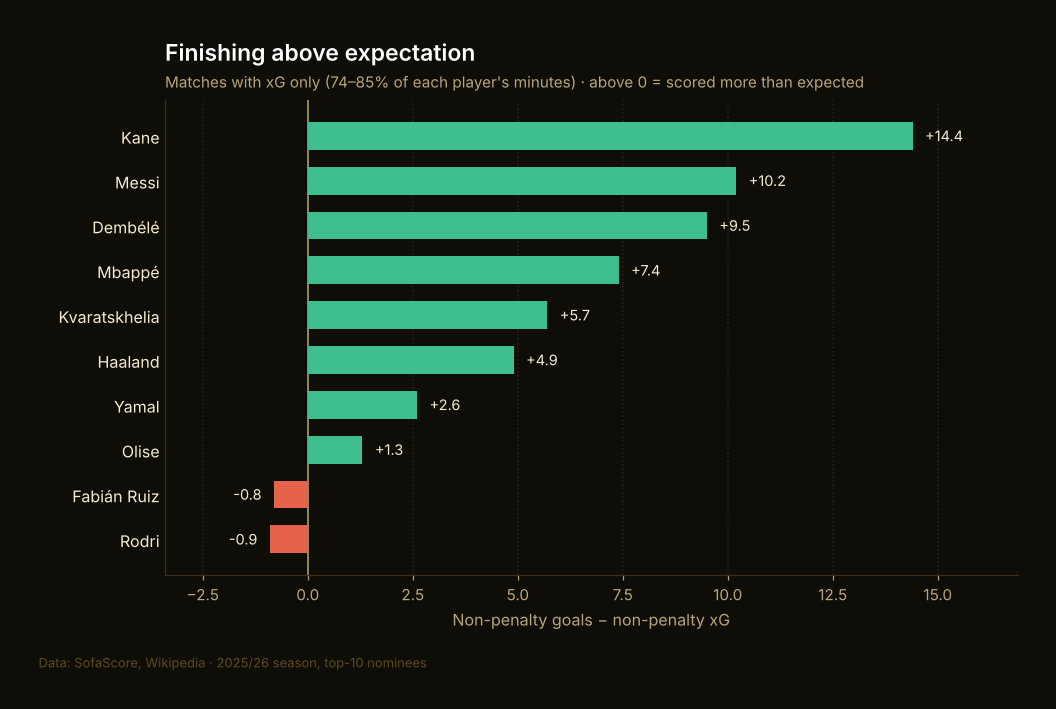

In [14]:
fig = charts.finishing(q5)

**Takeaway.** On the matches with xG, Kane scored **40 non-penalty goals from 25.6 npxG: +14.4**, the largest over-performance of the ten. Exceptional finishing - but also the kind of number that rarely repeats from season to season.

## 6. Can a simple index predict the vote?

Each nominee gets a percentile (0 = lowest, 1 = highest of the ten) on three components: **output** (NP G+A), **trophies** (weighted trophy score) and **big games** (G+A in UCL and World Cup knockouts). The index weights them **40 / 35 / 25** - the same logic as the DAX measures of the Power BI model.

In [15]:
show_sql("04")

```sql
-- Q4. Can a simple index predict the vote?
-- Percentile of each nominee on output, trophies and big games (0 = lowest, 1 = highest of the ten),
-- weighted by IndexWeights, ranked and compared with the actual ranking. Same logic as the DAX measures.
WITH pct AS (
    SELECT player, vote_rank,
           percent_rank() OVER (ORDER BY np_ga)           AS pctl_output,
           percent_rank() OVER (ORDER BY trophy_score)    AS pctl_trophies,
           percent_rank() OVER (ORDER BY big_stage_ko_ga) AS pctl_big_games
    FROM v_nominee
),
w AS (
    SELECT max(Weight) FILTER (WHERE Component = 'Output')   AS w_output,
           max(Weight) FILTER (WHERE Component = 'Trophies') AS w_trophies,
           max(Weight) FILTER (WHERE Component = 'BigGames') AS w_big_games
    FROM IndexWeights
),
idx AS (
    SELECT pct.*,
           w_output * pctl_output + w_trophies * pctl_trophies + w_big_games * pctl_big_games AS bdo_index
    FROM pct CROSS JOIN w
)
SELECT
    vote_rank,
    player,
    round(pctl_output, 3)                                 AS pctl_output,
    round(pctl_trophies, 3)                               AS pctl_trophies,
    round(pctl_big_games, 3)                              AS pctl_big_games,
    round(bdo_index, 3)                                   AS bdo_index,
    dense_rank() OVER (ORDER BY round(bdo_index, 6) DESC) AS index_rank,
    dense_rank() OVER (ORDER BY round(bdo_index, 6) DESC) - vote_rank AS rank_gap
FROM idx
ORDER BY vote_rank;
```

In [16]:
q4 = run(con, "04")
rest = q4[q4.vote_rank > 1]
rho_rest, p_rest = spearmanr(rest.vote_rank, rest.index_rank)
display(q4)
print(f"Places 2-10: Spearman rho = {rho_rest:+.2f} (p = {p_rest:.2f}, n = 9)")

,vote_rank,player,pctl_output,pctl_trophies,pctl_big_games,bdo_index,index_rank,rank_gap
0,1,Harry Kane,0.67,0.33,1.00,0.63,1,0
1,2,Kylian Mbappé,0.56,0.00,0.56,0.36,9,7
2,3,Lamine Yamal,0.44,0.67,0.22,0.47,7,4
3,4,Rodri,0.00,0.56,0.00,0.19,10,6
4,5,Lionel Messi,1.00,0.11,0.44,0.55,5,0
5,6,Khvicha Kvaratskhelia,0.22,0.78,0.78,0.56,4,-2
6,7,Ousmane Dembélé,0.33,0.78,0.78,0.60,2,-5
7,8,Erling Haaland,0.89,0.22,0.22,0.49,6,-2
8,9,Michael Olise,0.78,0.33,0.56,0.57,3,-6
9,10,Fabián Ruiz,0.11,1.00,0.11,0.42,8,-2


Places 2-10: Spearman rho = -0.45 (p = 0.22, n = 9)


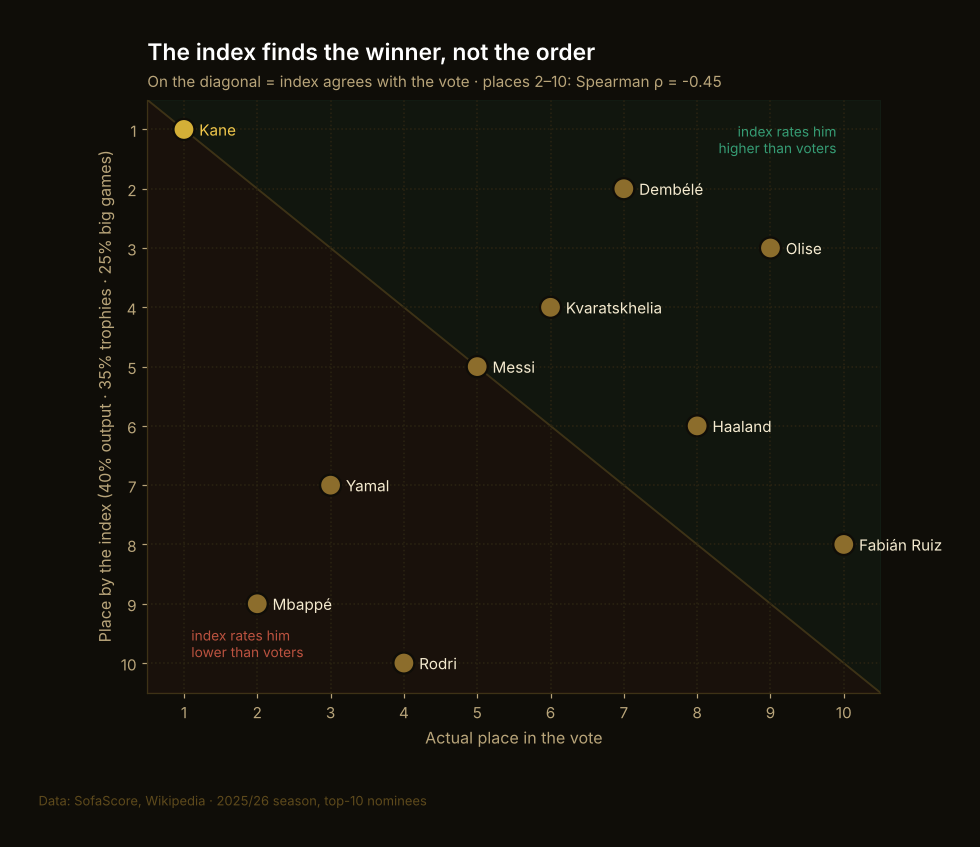

In [17]:
fig = charts.index_vs_vote(q4, rho_rest)

The index puts Kane first, but for places 2–10 it runs, if anything, *against* the vote (ρ = −0.45, not significant with nine players). Mbappé (2nd) is 9th by the index, Rodri (4th) is 10th, Dembélé (7th) is 2nd.

**Is that just a bad choice of weights?** Try every weighting in steps of 5%:

In [18]:
P = q4[["pctl_output", "pctl_trophies", "pctl_big_games"]].to_numpy()
rows = []
for wo in np.arange(0, 1.0001, 0.05):
    for wt in np.arange(0, 1.0001 - wo, 0.05):
        w = np.array([wo, wt, 1 - wo - wt])
        idx = P @ w
        rows.append({
            "w_output": wo, "w_trophies": wt, "w_big_games": w[2],
            "picks_winner": bool(idx[0] > np.delete(idx, 0).max()),     # row 0 = the winner
            "rho_full_vote": spearmanr(q4.vote_rank, -idx)[0],
        })
grid = pd.DataFrame(rows)
print(f"{len(grid)} weightings: the index picks the winner in {grid.picks_winner.mean():.0%} of them; "
      f"best agreement with the whole top 10: rho = {grid.rho_full_vote.max():+.2f}")
grid.nlargest(5, "rho_full_vote").round(2)

231 weightings: the index picks the winner in 40% of them; best agreement with the whole top 10: rho = +0.28


,w_output,w_trophies,w_big_games,picks_winner,rho_full_vote
0,0.00,0.00,1.00,True,0.28
1,0.00,0.05,0.95,True,0.27
2,0.00,0.10,0.90,True,0.27
165,0.50,0.00,0.50,True,0.27
23,0.05,0.10,0.85,True,0.26


**Takeaway.** The 40/35/25 index picks the winner, but only about 40% of all weightings do and no weighting of output, trophies and big games explains the full top 10: the best achievable agreement is weak (ρ ≈ +0.28, with all weight on big games). What these three numbers miss - reputation, narrative, position (Rodri, a defensive midfielder, finished 4th with 2 goals) - is what decides places 2–10.

## 7. How close was the vote?

In [19]:
show_sql("07")

```sql
-- Q7. How close was the vote?
-- Points, share of the top-10 points and the gap to the next player.
SELECT
    vote_rank,
    player,
    points,
    round(100.0 * points / sum(points) OVER (), 1)          AS share_of_top10_pct,
    points - lead(points) OVER (ORDER BY vote_rank)         AS lead_over_next,
    round(100.0 * (points - lead(points) OVER (ORDER BY vote_rank))
          / lead(points) OVER (ORDER BY vote_rank), 1)      AS lead_over_next_pct
FROM v_nominee
ORDER BY vote_rank;
```

,vote_rank,player,points,share_of_top10_pct,lead_over_next,lead_over_next_pct
0,1,Harry Kane,1055,17.2,28,2.7
1,2,Kylian Mbappé,1027,16.7,146,16.6
2,3,Lamine Yamal,881,14.4,155,21.3
3,4,Rodri,726,11.8,114,18.6
4,5,Lionel Messi,612,10.0,71,13.1
5,6,Khvicha Kvaratskhelia,541,8.8,123,29.4
6,7,Ousmane Dembélé,418,6.8,40,10.6
7,8,Erling Haaland,378,6.2,82,27.7
8,9,Michael Olise,296,4.8,95,47.3
9,10,Fabián Ruiz,201,3.3,<NA>,NaN


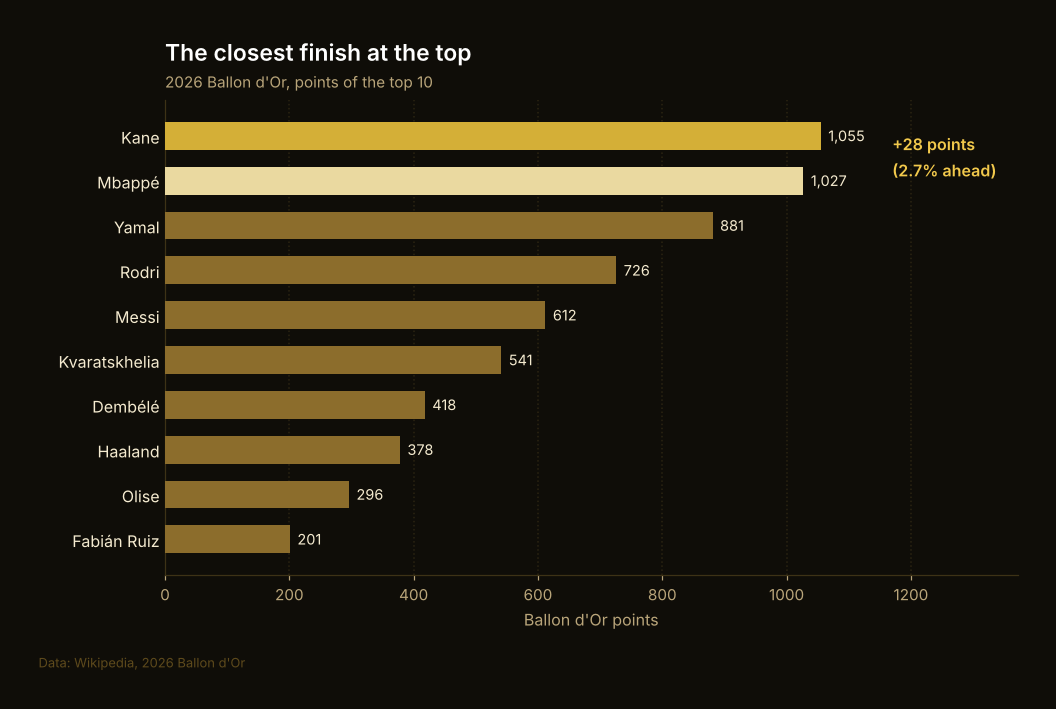

In [20]:
q7 = run(con, "07")
display(q7)
fig = charts.vote_margin(q7)

**Takeaway.** **1,055 to 1,027**: Kane won by 28 points, a **2.7%** margin - the smallest gap between any two neighbours in the top 10.

## 8. The winner's season, match by match

In [21]:
show_sql("06")

```sql
-- Q6. How did the winner's season unfold?
-- Rolling five-match G+A and cumulative goals, match by match (window functions).
SELECT
    match_date,
    competition,
    opponent,
    result,
    goals,
    assists,
    round(avg(goals + assists) OVER w5, 2)                                   AS ga_rolling_5,
    (sum(goals) OVER (ORDER BY match_date ROWS UNBOUNDED PRECEDING))::INT      AS goals_cumulative,
    rating
FROM v_match
WHERE player = (SELECT player FROM v_nominee WHERE vote_rank = 1)
WINDOW w5 AS (ORDER BY match_date ROWS BETWEEN 4 PRECEDING AND CURRENT ROW)
ORDER BY match_date;
```

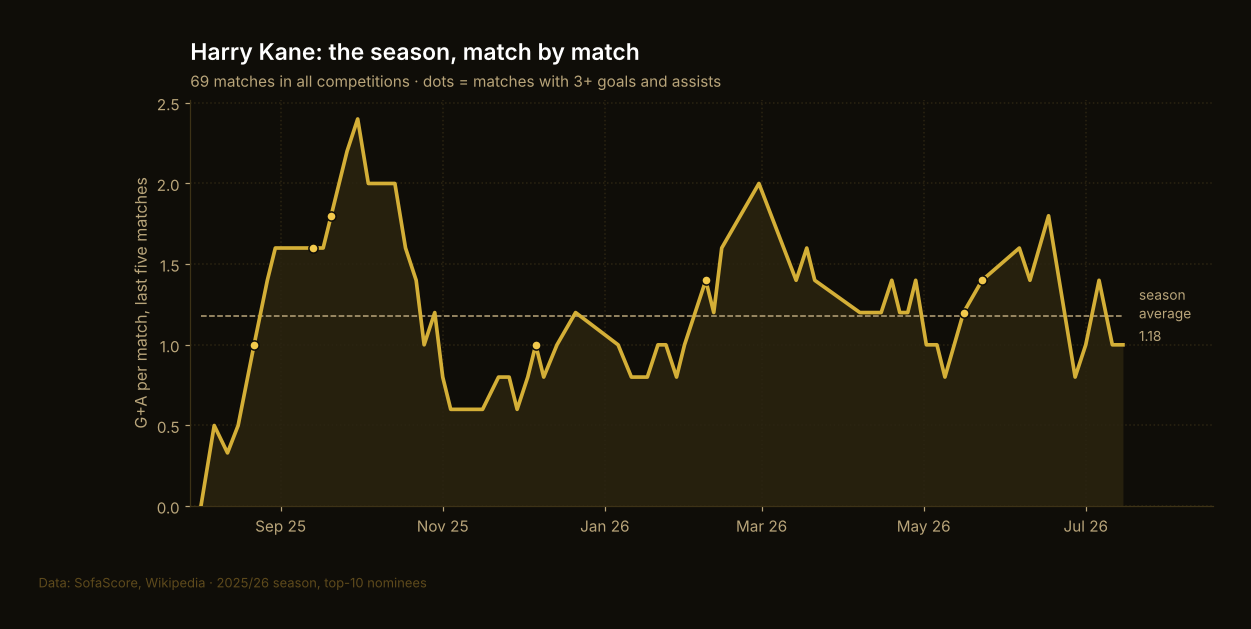

In [22]:
q6 = run(con, "06")
fig = charts.winner_form(q6, "Harry Kane")

A blistering September (2.4 G+A per match over the five games to 30 September), a quieter November–January, then a second peak in late February (six goals in three Bundesliga matches).

## 9. Conclusions and limitations

**Conclusions**
1. **Volume won.** The winner led in goals (74) and big-stage knockout output (12 G+A), not in efficiency (5th per 90) - and a quarter of his goals were penalties.
2. **Trophies were not decisive.** The most decorated nominee (Fabián Ruiz, 5 trophies including the UCL and the World Cup) finished last of the ten; the runner-up won nothing.
3. **Statistics pick the winner, not the order.** A 40/35/25 index finds Kane, but no weighting of output, trophies and big games explains places 2–10.
4. **It was close.** 28 points (2.7%) separated Kane and Mbappé.

**Limitations**
- One season, ten players: the correlations are descriptive, not significant.
- About 20% of minutes have no xG; xG comparisons use the covered matches only (season totals with an estimate are in `npxGIncEst`).
- Ratings are SofaScore's; trophy weights are a modelling choice (`etl/config.yaml`).
- Voting depends on things no match log records (reputation, position, narrative).